# Hotel channel attribution with pymc-marketing (GPU)

NUTS sampling runs on the GPU via numpyro/JAX (kernel `mmm-pymc`, WSL2).

Hospitality channel attribution with pymc-marketing (1.3.x API).

NOTE ON NAMING: classic Multi-Touch Attribution (MTA) works on user-level touchpoint
journeys. This script uses *aggregate* weekly spend and `pymc_marketing.mmm.MMM`, i.e.
a Marketing Mix Model. It delivers the attribution outputs MTA is usually asked for
(attribution share vs spend share, ROAS, optimal budget) from aggregate data.

Run in WSL2, env `mmm-pymc`:
    python hotel_mta_mmm.py --quick      # smoke test
    python hotel_mta_mmm.py              # full run (numpyro NUTS)
    python hotel_mta_mmm.py --data my.csv

HOW A MARKETER SHOULD READ THE RESULTS
  Adstock (Weibull PDF): the curve shows *when* a week of spend turns into bookings.
    A peak at lag 0-1 = harvest channel (search, email, OTA). A peak at lag 3-6 with a
    long tail = planning-phase channel (social "dreaming"). Judging the latter on
    same-week ROAS undersells it.
  Saturation (logistic): compare current weekly spend with the bend of the curve.
    On the flat part -> extra budget is mostly wasted. On the steep part -> room to scale.
  Attribution vs spend share: share of modelled bookings minus share of spend.
    Positive gap = channel delivers more than its budget share (candidate to scale).
  Marginal vs average ROAS: a channel with a high average ROAS can still be saturated
    at the margin; the optimizer works on the margin.
  Caveats: spend chases demand (confounding), channels are correlated, and 3 years of
  weekly data identify curve *shapes* weakly. Calibrate with lift tests where possible.

In [1]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

import warnings
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import jax
from pymc_extras.prior import Prior

from pymc_marketing.mmm import MMM, LogisticSaturation, WeibullPDFAdstock

warnings.filterwarnings("ignore")
%matplotlib inline
print("JAX devices:", jax.devices())
assert any(d.platform == "gpu" for d in jax.devices()), "GPU not visible to JAX"

/home/rama/miniforge3/envs/mmm-pymc/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX devices: [CudaDevice(id=0)]


## Schema / config

In [2]:
DATE = "date"
TARGET = "bookings"
CHANNELS = ["spend_paid_search", "spend_paid_social", "spend_ota_ads",
            "spend_metasearch", "spend_email"]
CONTROLS = ["adr_index", "holiday_thanksgiving", "holiday_christmas", "holiday_spring_break"]
L_MAX = 10
OUT = Path("outputs")

# Prior beliefs per channel (order = CHANNELS).
# Weibull PDF adstock: `lam` ~ scale (weeks to peak/spread), `k` ~ shape.
#   search / OTA / metasearch / email: short window -> small lam
#   paid social: long planning phase -> larger lam
ADSTOCK_LAM_MU = np.array([1.0, 3.5, 1.5, 1.5, 1.0])
ADSTOCK_K_MU = np.array([1.5, 2.5, 1.8, 1.8, 1.5])

QUICK = False          # True = short CPU smoke test
DATA_PATH = None       # CSV path, or None for synthetic data
TARGET_ACCEPT = 0.99   # raised from 0.95 to reduce divergences
OUT.mkdir(exist_ok=True)

## Data

In [3]:
def make_data(n_weeks: int = 156, seed: int = 11) -> pd.DataFrame:
    """Synthetic weekly hotel data, with the ground truth stored in `df.attrs`."""
    rng = np.random.default_rng(seed)
    t = np.arange(n_weeks)
    dates = pd.date_range("2022-01-03", periods=n_weeks, freq="W-MON")
    season = (0.6 * np.sin(2 * np.pi * (t - 14) / 52.18) + 0.15 * np.cos(4 * np.pi * t / 52.18))
    df = pd.DataFrame({DATE: dates})

    base = dict(zip(CHANNELS, [9e3, 7e3, 8e3, 6e3, 2e3]))
    for c in CHANNELS:
        s = base[c] * (1 + 0.5 * season) * rng.gamma(6, 1 / 6, n_weeks)   # spend chases demand
        s[rng.random(n_weeks) < 0.05] = 0.0
        df[c] = s

    wk = dates.isocalendar().week.to_numpy()
    df["holiday_thanksgiving"] = np.isin(wk, [47, 48]).astype(float)
    df["holiday_christmas"] = np.isin(wk, [51, 52]).astype(float)
    df["holiday_spring_break"] = np.isin(wk, [11, 12, 13]).astype(float)
    df["adr_index"] = 100 + 12 * season + rng.normal(0, 2.5, n_weeks)

    # ground-truth response
    lam_t = np.array([0.8, 3.0, 1.2, 1.2, 0.8]); k_t = np.array([1.4, 2.4, 1.6, 1.6, 1.4])
    sat_t = np.array([2.5, 2.0, 2.8, 3.0, 4.0]); beta_t = np.array([420, 300, 330, 260, 120])
    x = df[CHANNELS].to_numpy() / df[CHANNELS].max().to_numpy()
    resp = np.zeros_like(x)
    lags = np.arange(1, L_MAX + 1)
    for j in range(len(CHANNELS)):
        w = (k_t[j] / lam_t[j]) * (lags / lam_t[j]) ** (k_t[j] - 1) * np.exp(-((lags / lam_t[j]) ** k_t[j]))
        w = w / w.sum()
        ad = np.convolve(x[:, j], w)[:n_weeks]
        resp[:, j] = beta_t[j] * (1 - np.exp(-sat_t[j] * ad)) / (1 + np.exp(-sat_t[j] * ad))
    y = (1800 + 900 * season - 9 * (df["adr_index"] - 100) + 350 * df["holiday_thanksgiving"]
         + 500 * df["holiday_christmas"] + 400 * df["holiday_spring_break"] + resp.sum(1)
         + rng.normal(0, 60, n_weeks))
    df[TARGET] = np.maximum(y, 0).round()
    df.attrs["true_contribution_share"] = dict(zip(CHANNELS, resp.sum(0) / resp.sum()))
    return df

In [4]:
def validate(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(DATE).reset_index(drop=True)
    full = pd.date_range(df[DATE].min(), df[DATE].max(), freq="W-MON")
    missing = full.difference(pd.DatetimeIndex(df[DATE]))
    print(f"[validate] rows={len(df)} missing weeks={len(missing)}")
    assert not df[[TARGET, *CHANNELS, *CONTROLS]].isna().any().any(), "NaNs in inputs"
    print("[validate] zero-spend share:\n", (df[CHANNELS] == 0).mean().round(3).to_string())
    cols = CHANNELS + [c for c in CONTROLS if df[c].nunique() > 1]
    vif = pd.Series(np.diag(np.linalg.pinv(np.corrcoef(df[cols].to_numpy().T))), index=cols).round(2)
    print("[validate] VIF:\n", vif.to_string())
    return df

In [5]:
df = pd.read_csv(DATA_PATH, parse_dates=[DATE]) if DATA_PATH else make_data()
df = validate(df)
df.head(3)

[validate] rows=156 missing weeks=0
[validate] zero-spend share:
 spend_paid_search    0.051
spend_paid_social    0.064
spend_ota_ads        0.045
spend_metasearch     0.045
spend_email          0.019
[validate] VIF:
 spend_paid_search       1.40
spend_paid_social       1.27
spend_ota_ads           1.19
spend_metasearch        1.09
spend_email             1.26
adr_index               1.98
holiday_thanksgiving    1.08
holiday_christmas       1.07
holiday_spring_break    1.08


,date,spend_paid_search,spend_paid_social,spend_ota_ads,spend_metasearch,spend_email,holiday_thanksgiving,holiday_christmas,holiday_spring_break,adr_index,bookings
0,2022-01-03,6699.660459,12210.278558,7592.006058,5038.942669,773.232263,0.0,0.0,0.0,92.985878,1793.0
1,2022-01-10,10561.609475,5418.806134,2042.274770,2671.697196,1689.803323,0.0,0.0,0.0,93.541264,1881.0
2,2022-01-17,5750.771962,1381.989068,5343.630124,2623.196480,1437.902981,0.0,0.0,0.0,91.146609,1906.0


## Model

In [6]:
def build_model(df: pd.DataFrame) -> MMM:
    share = (df[CHANNELS].sum() / df[CHANNELS].sum().sum()).to_numpy()
    n = len(CHANNELS)
    adstock = WeibullPDFAdstock(
        l_max=L_MAX,
        priors={
            "lam": Prior("Gamma", mu=ADSTOCK_LAM_MU, sigma=1.0, dims="channel"),
            "k": Prior("Gamma", mu=ADSTOCK_K_MU, sigma=0.8, dims="channel"),
        },
    )
    saturation = LogisticSaturation(
        priors={
            "lam": Prior("Gamma", mu=3.0, sigma=1.5, dims="channel"),
            # HalfNormal -> media effects are strictly positive; wider for bigger spenders
            "beta": Prior("HalfNormal", sigma=np.clip(share * n, 0.3, None) * 0.5, dims="channel"),
        }
    )
    return MMM(
        date_column=DATE, target_column=TARGET, channel_columns=CHANNELS,
        control_columns=CONTROLS, adstock=adstock, saturation=saturation,
        yearly_seasonality=3,
    )


def _date_first(da, n: int) -> np.ndarray:
    da = da.squeeze(drop=True)
    other = [d for d in da.dims if d != "date"]
    return da.transpose("date", *other).values.reshape(n, -1)

## 1. Prior predictive check

Sampling: [adstock_k, adstock_lam, gamma_control, gamma_fourier, intercept_contribution, saturation_beta, saturation_lam, y, y_sigma]


[prior] non-finite draws: 4.3%


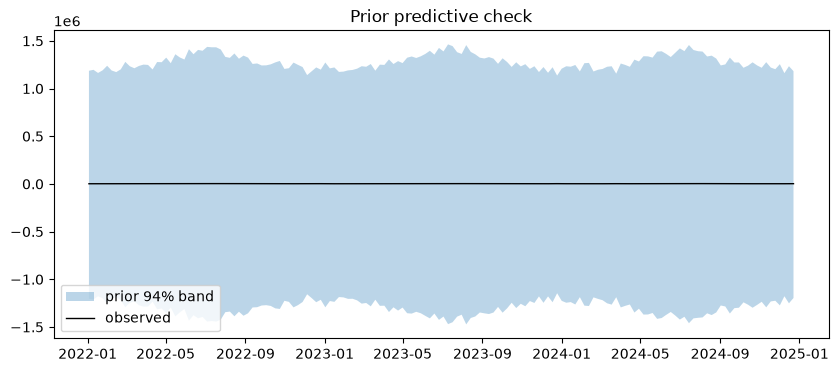

[prior] observed 1793-3406; prior band -1472563..1462778


In [7]:
X, y = df.drop(columns=[TARGET]), df[TARGET]
mmm = build_model(df)
prior = mmm.sample_prior_predictive(X, y, samples=300)
t_scale = float(mmm.get_scales_as_xarray()["target_scale"])
pp = _date_first(prior["y"], len(df)) * t_scale
print(f"[prior] non-finite draws: {np.mean(~np.isfinite(pp)):.1%}")
lo, hi = np.nanpercentile(np.where(np.isfinite(pp), pp, np.nan), [3, 97], axis=1)
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(df[DATE], lo, hi, alpha=0.3, label="prior 94% band")
ax.plot(df[DATE], y, "k", lw=1, label="observed"); ax.legend()
ax.set_title("Prior predictive check"); fig.savefig(OUT / "prior_predictive.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"[prior] observed {y.min():.0f}-{y.max():.0f}; prior band {lo.min():.0f}..{hi.max():.0f}")

## 2. Fit (numpyro NUTS, chains vectorized on the GPU)

In [8]:
mmm = build_model(df)   # fresh instance
sk = dict(draws=300, tune=300, chains=2) if QUICK else \
    dict(draws=1500, tune=1500, chains=4, target_accept=TARGET_ACCEPT, nuts_sampler="numpyro",
         nuts_sampler_kwargs={"chain_method": "vectorized"})
mmm.fit(X, y, random_seed=42, **sk)
idata = mmm.idata

NUTS[numpyro]: [adstock_lam, adstock_k, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


  0%|          | 0/3000 [00:00<?, ?it/s]

warmup:   0%|          | 0/3000 [00:19<?, ?it/s]

warmup:   2%|▏         | 53/3000 [00:20<18:46,  2.62it/s]

warmup:   2%|▏         | 54/3000 [00:20<18:40,  2.63it/s]

warmup:   2%|▏         | 55/3000 [00:20<18:35,  2.64it/s]

... (2,941 outputs left out)

sample: 100%|██████████| 3000/3000 [17:47<00:00,  2.81it/s]

There were 358 divergences after tuning. Increase `target_accept` or reparameterize.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


## 3. Convergence

In [9]:
keep = ["adstock_lam", "adstock_k", "saturation_lam", "saturation_beta"]
summ = az.summary(idata.posterior, var_names=keep)
summ.to_csv(OUT / "summary.csv")
div = int(idata.sample_stats["diverging"].sum())
print(summ[["mean", "sd", "r_hat", "ess_bulk"]].round(3).to_string())
print(f"[diag] max r_hat={summ['r_hat'].max():.3f} min ess_bulk={summ['ess_bulk'].min():.0f} divergences={div}")
if summ["r_hat"].max() > 1.01 or div:
    print("  WARNING: convergence issues - raise tune/target_accept or tighten priors")

                                     mean     sd r_hat ess_bulk
adstock_lam[spend_paid_search]       1.03   0.37  1.00      566
adstock_lam[spend_paid_social]       3.41  0.218  1.01     1356
adstock_lam[spend_ota_ads]           1.51   0.27  1.00      426
adstock_lam[spend_metasearch]        1.14   0.24  1.01      559
adstock_lam[spend_email]             0.43   0.32  1.09       38
adstock_k[spend_paid_search]         1.66   0.71  1.01      677
adstock_k[spend_paid_social]         3.72   0.64  1.00     1256
adstock_k[spend_ota_ads]             1.39   0.44  1.00      390
adstock_k[spend_metasearch]          1.74   0.63  1.01      530
adstock_k[spend_email]               1.67   0.74  1.02      542
saturation_lam[spend_paid_search]     4.3   1.05  1.02      240
saturation_lam[spend_paid_social]    2.27    1.1  1.00      666
saturation_lam[spend_ota_ads]        1.98   0.78  1.02      290
saturation_lam[spend_metasearch]     2.82   0.89  1.00      771
saturation_lam[spend_email]           3.

## 4. Posterior predictive check

Sampling: [y]


[ppc] R2=0.987 MAPE=1.55% coverage94=96%


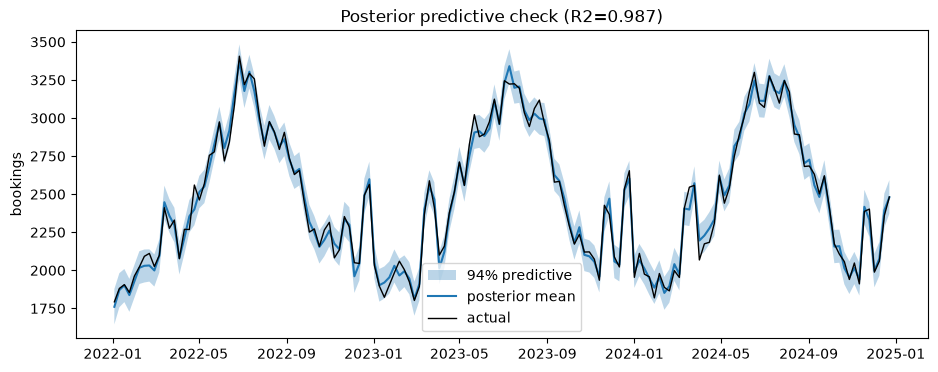

In [10]:
mmm.sample_posterior_predictive(X, extend_idata=True, combined=True)
arr = _date_first(mmm.idata.posterior_predictive["y"], len(df)) * t_scale
m = arr.mean(1); lo, hi = np.percentile(arr, [3, 97], axis=1)
r2 = 1 - ((y - m) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"[ppc] R2={r2:.3f} MAPE={np.mean(np.abs((y - m) / y)):.2%} coverage94={np.mean((y >= lo) & (y <= hi)):.0%}")
fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(df[DATE], lo, hi, alpha=0.3, label="94% predictive")
ax.plot(df[DATE], m, label="posterior mean"); ax.plot(df[DATE], y, "k", lw=1, label="actual")
ax.set(title=f"Posterior predictive check (R2={r2:.3f})", ylabel=TARGET); ax.legend()
fig.savefig(OUT / "ppc.png", dpi=130, bbox_inches="tight"); plt.show()

## 5. Attribution: share of modelled bookings vs share of spend

In [11]:
cf = mmm.compute_counterfactual_contributions_dataset()
contrib = np.stack([cf[c].transpose("date", ...).values.reshape(len(df), -1) for c in CHANNELS], 1)  # T,C,S
tot = contrib.sum(0)
attr = tot / tot.sum(0, keepdims=True)
spend = df[CHANNELS].sum().to_numpy()
spend_share = spend / spend.sum()
roas = tot / spend[:, None]
tab = pd.DataFrame({
    "spend_share": spend_share,
    "attrib_share": attr.mean(1),
    "attrib_p3": np.percentile(attr, 3, 1), "attrib_p97": np.percentile(attr, 97, 1),
    "bookings_per_1k": roas.mean(1) * 1e3,
    "roas_p3": np.percentile(roas, 3, 1) * 1e3, "roas_p97": np.percentile(roas, 97, 1) * 1e3,
}, index=CHANNELS)
tab["gap_pp"] = (tab["attrib_share"] - tab["spend_share"]) * 100
if "true_contribution_share" in df.attrs:
    tab["true_share"] = pd.Series(df.attrs["true_contribution_share"])
tab.to_csv(OUT / "attribution.csv")
tab.round(3)

,spend_share,attrib_share,attrib_p3,attrib_p97,bookings_per_1k,roas_p3,roas_p97,gap_pp,true_share
spend_paid_search,0.283,0.258,0.200,0.319,20.969,15.642,26.870,-2.531,0.268
spend_paid_social,0.219,0.150,0.090,0.216,15.808,9.080,23.533,-6.908,0.164
spend_ota_ads,0.245,0.269,0.209,0.336,25.228,19.137,32.542,2.345,0.238
spend_metasearch,0.186,0.209,0.153,0.273,25.905,18.588,34.425,2.340,0.212
spend_email,0.066,0.114,0.072,0.166,39.586,24.205,59.441,4.754,0.118


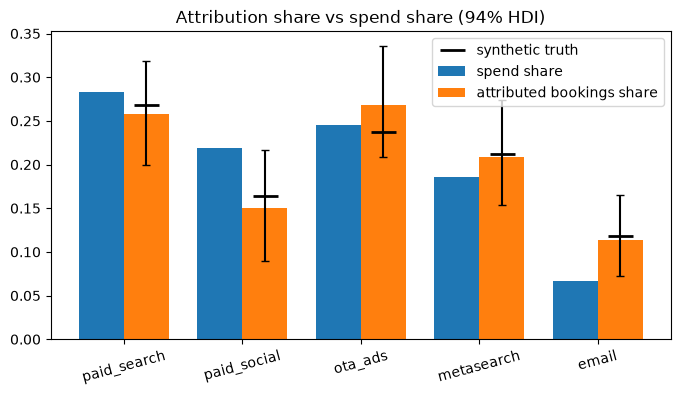

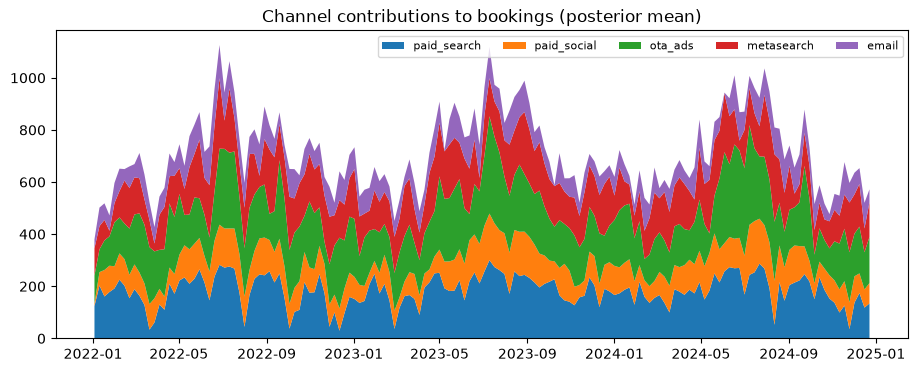

In [12]:
fig, ax = plt.subplots(figsize=(8, 4)); xs = np.arange(len(CHANNELS)); w = 0.38
ax.bar(xs - w / 2, tab["spend_share"], w, label="spend share")
ax.bar(xs + w / 2, tab["attrib_share"], w, label="attributed bookings share",
       yerr=[tab["attrib_share"] - tab["attrib_p3"], tab["attrib_p97"] - tab["attrib_share"]], capsize=3)
if "true_share" in tab:
    ax.plot(xs + w / 2, tab["true_share"], "k_", ms=18, mew=2, label="synthetic truth")
ax.set_xticks(xs, [c.replace("spend_", "") for c in CHANNELS], rotation=15); ax.legend()
ax.set_title("Attribution share vs spend share (94% HDI)")
fig.savefig(OUT / "attribution_vs_spend.png", dpi=130, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(df[DATE], contrib.mean(2).T, labels=[c.replace("spend_", "") for c in CHANNELS])
ax.legend(ncol=5, fontsize=8); ax.set_title("Channel contributions to bookings (posterior mean)")
fig.savefig(OUT / "contributions_over_time.png", dpi=130, bbox_inches="tight"); plt.show()

## Adstock and saturation curves

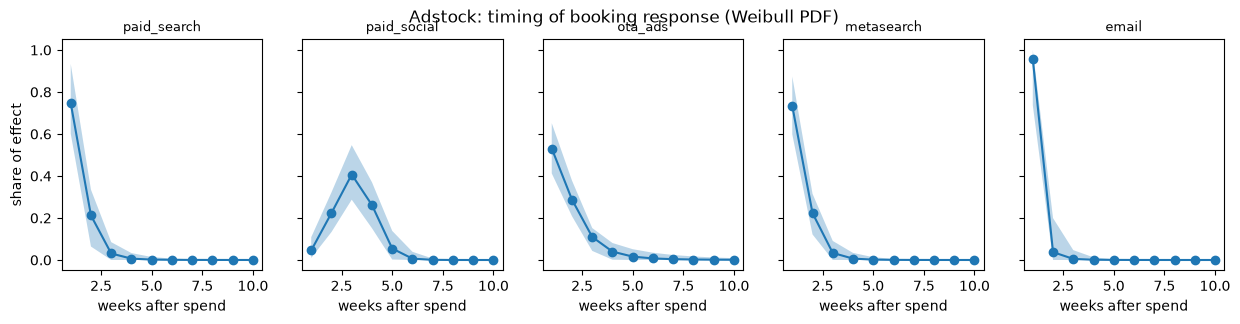

Sampling: []


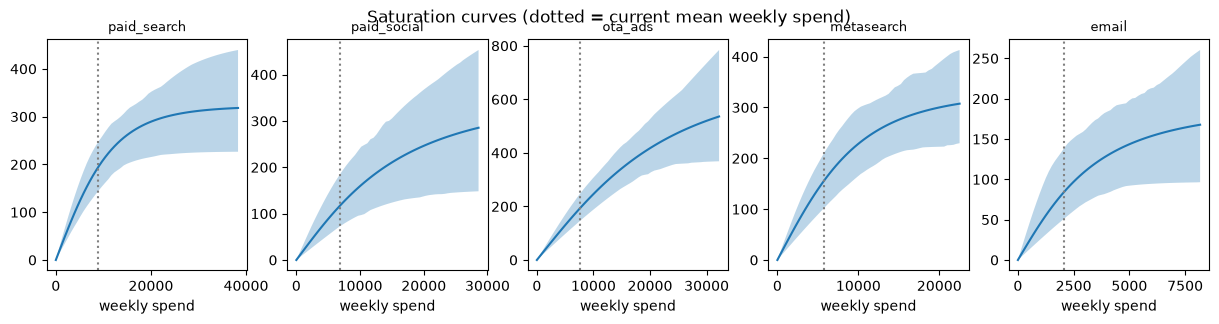

In [13]:
def plot_curves(mmm: MMM, df: pd.DataFrame) -> None:
    """Adstock (when bookings arrive) and saturation (diminishing returns) per channel."""
    post = mmm.idata.posterior.to_dataset().stack(s=("chain", "draw"))
    lam = post["adstock_lam"].transpose("s", "channel").values
    k = post["adstock_k"].transpose("s", "channel").values
    lags = np.arange(1, L_MAX + 1)[None, :, None]
    w = (k[:, None, :] / lam[:, None, :]) * (lags / lam[:, None, :]) ** (k[:, None, :] - 1) \
        * np.exp(-((lags / lam[:, None, :]) ** k[:, None, :]))
    w = w / w.sum(1, keepdims=True)
    fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3), sharey=True)
    for j, ax in enumerate(axes):
        ax.fill_between(lags[0, :, 0], *np.percentile(w[:, :, j], [3, 97], 0), alpha=0.3)
        ax.plot(lags[0, :, 0], w[:, :, j].mean(0), marker="o")
        ax.set_title(CHANNELS[j].replace("spend_", ""), fontsize=9); ax.set_xlabel("weeks after spend")
    axes[0].set_ylabel("share of effect")
    fig.suptitle("Adstock: timing of booking response (Weibull PDF)")
    fig.savefig(OUT / "adstock_curves.png", dpi=130, bbox_inches="tight"); plt.show()

    try:
        curve = mmm.sample_saturation_curve(max_value=1.5, num_points=60, num_samples=200, original_scale=True)
        fig, axes = plt.subplots(1, len(CHANNELS), figsize=(15, 3))
        cur = df[CHANNELS].mean()
        for j, (ax, c) in enumerate(zip(axes, CHANNELS)):
            cj = curve.sel(channel=c)
            xdim = [d for d in cj.dims if d not in ("sample", "chain", "draw")][0]
            sdims = [d for d in cj.dims if d != xdim]
            m = cj.mean(sdims); q = cj.quantile([0.03, 0.97], dim=sdims)
            xs = cj[xdim].values * (df[c].max() if cj[xdim].values.max() <= 2 else 1)
            ax.fill_between(xs, q.values[0], q.values[1], alpha=0.3); ax.plot(xs, m.values)
            ax.axvline(cur[c], color="gray", ls=":"); ax.set_title(c.replace("spend_", ""), fontsize=9)
            ax.set_xlabel("weekly spend")
        fig.suptitle("Saturation curves (dotted = current mean weekly spend)")
        fig.savefig(OUT / "saturation_curves.png", dpi=130, bbox_inches="tight"); plt.show()
    except Exception as e:  # plotting helper API varies across versions
        print("  (saturation plot skipped:", type(e).__name__, e, ")")

plot_curves(mmm, df)

## 6. Optimal budget allocation

[opt] total budget 297,814 over 13 weeks, success=True


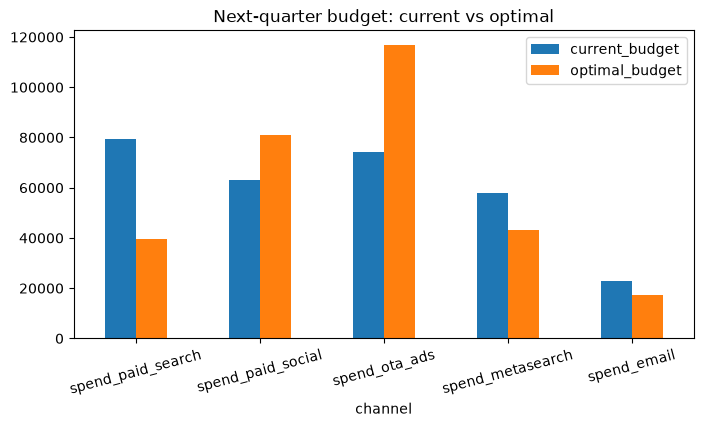

,optimal_budget,current_budget,change_pct
channel,,,
spend_paid_search,39580.8,79595.0,-50.3
spend_paid_social,80919.1,63215.4,28.0
spend_ota_ads,116790.4,74214.2,57.4
spend_metasearch,43112.2,57753.1,-25.4
spend_email,17411.3,23036.0,-24.4


In [14]:
horizon = 13
last = pd.Timestamp(df[DATE].max())
start, end = last + pd.Timedelta(weeks=1), last + pd.Timedelta(weeks=horizon)
total = float(df[CHANNELS].tail(horizon).sum().sum())
opt = mmm.budget_optimizer(start_date=start, end_date=end)
res = opt.allocate_budget(total_budget=total)
alloc = res.budgets.to_series().to_frame("optimal_budget")
alloc["current_budget"] = df[CHANNELS].tail(horizon).sum()
alloc["change_pct"] = (alloc["optimal_budget"] / alloc["current_budget"] - 1) * 100
alloc.to_csv(OUT / "optimal_allocation.csv")
print(f"[opt] total budget {total:,.0f} over {horizon} weeks, success={res.scipy_result.success}")
ax = alloc[["current_budget", "optimal_budget"]].plot.bar(figsize=(8, 4), rot=15)
ax.set_title("Next-quarter budget: current vs optimal")
ax.figure.savefig(OUT / "budget_allocation.png", dpi=130, bbox_inches="tight"); plt.show()
alloc.round(1)